<a href="https://colab.research.google.com/github/AnthoChevez/IA/blob/main/PRACTICA_3_IA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PRACTICA 3

**Nombre:** ANTHONY CHEVEZ  
**Fecha:** 13 de noviembre de 2026  
**Materia:** INTELIGENCIA ARTIFICIAL

**El perceptrón**

Implementación manual de un clasificador binario con Python. Se usa Matplotlib para las gráficas.

## Fase 1 · Exploración del conjunto de datos

### Pregunta 1.a — Inspección inicial

¿Qué representa cada fila de `X`? ¿Qué representa cada valor de `y`? ¿Por qué es un problema de clasificación binaria?

In [ ]:
X = [
    [1, 7], [1, 3], [3, 4], [4, 6], [4, 2], [6, 6], [6, 2],
    [6, 0], [7, 4], [9, 3], [9, 1], [11, 1], [12, 3], [16, 2],
    [4, 8], [6, 8], [8, 9], [9, 7], [10, 11], [12, 9],
    [12, 6], [14, 7], [16, 4],
]
y = [-1] * 14 + [1] * 9

conteo = {-1: 0, 1: 0}
for etiqueta in y:
    conteo[etiqueta] += 1

print(f"Total de instancias = {len(X)}")
print(f"Variables de entrada = {len(X[0])} (x₁ y x₂)")
print(f"Número de clases = {len(conteo)}")
for etiqueta, cantidad in conteo.items():
    print(f"Clase {etiqueta:+d} → {cantidad} puntos")

Total de instancias = 23
Variables de entrada = 2 (x₁ y x₂)
Número de clases = 2
Clase -1 → 14 puntos
Clase +1 → 9 puntos


**Respuesta**

Cada fila de `X` es un punto con dos coordenadas: $x_1$ y $x_2$. En `y`, en esa misma posición, está la clase del punto. Conté 23 puntos: 14 son de la clase −1 y 9 de la clase +1. Como solo hay dos clases, es clasificación binaria.

### Pregunta 1.b — Separación visual

Al observar la gráfica, ¿parece posible separar las dos clases mediante una sola recta? Justifica tu respuesta.

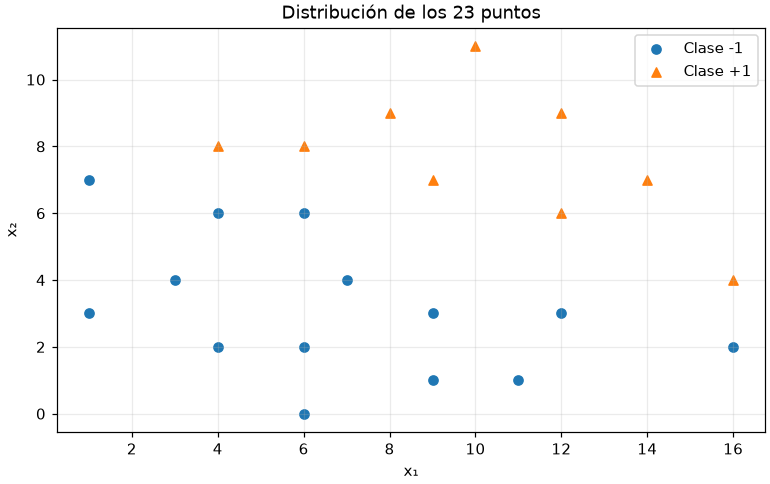

In [ ]:
import matplotlib.pyplot as plt

def graficar_puntos(ax, X, y):
    x1_negativos, x2_negativos = [], []
    x1_positivos, x2_positivos = [], []

    for i in range(len(X)):
        x1, x2 = X[i]
        if y[i] == -1:
            x1_negativos.append(x1)
            x2_negativos.append(x2)
        else:
            x1_positivos.append(x1)
            x2_positivos.append(x2)

    ax.scatter(x1_negativos, x2_negativos, marker="o", label="Clase -1")
    ax.scatter(x1_positivos, x2_positivos, marker="^", label="Clase +1")
    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")
    ax.grid(alpha=0.25)

fig, ax = plt.subplots(figsize=(7, 4.4), layout="constrained")
graficar_puntos(ax, X, y)
ax.set_title("Distribución de los 23 puntos")
ax.legend()
plt.show()

**Respuesta**

Sí, parece que una recta inclinada hacia abajo podría separarlos. Por ejemplo, en $x_1=4$ puede pasar entre las alturas 6 y 8. Más a la derecha, en $x_1=16$, puede pasar entre 2 y 4.

## Fase 2 · Fundamento del perceptrón

### Pregunta 2.a — Vector de pesos

¿Por qué hay tres pesos si cada instancia tiene dos variables? ¿Qué función cumple el sesgo?

In [ ]:
from random import Random

SEMILLA = 13
generador = Random(SEMILLA)

def initialize_weights():
    pesos = []
    for _ in range(3):
        pesos.append(generador.uniform(-0.5, 0.5))
    return pesos

w_initial = initialize_weights()
print("Pesos iniciales [w₀, w₁, w₂]")
print([round(peso, 6) for peso in w_initial])

Pesos iniciales [w₀, w₁, w₂]
[-0.240992, 0.185258, 0.184082]


**Respuesta**

Dos pesos van con las dos entradas. El tercero, $w_0$, es el sesgo. Sirve para mover la recta y permite que pase por un lugar distinto del origen. Usé la semilla 13 para obtener los mismos pesos iniciales al volver a ejecutar el cuaderno.

### Pregunta 2.b — Función de activación

¿Por qué se usan las etiquetas −1 y +1? ¿Qué ventaja tienen para la regla de aprendizaje?

In [ ]:
def activation(z):
    if z >= 0:
        return 1
    return -1

for z in [-2, 0, 2]:
    print(f"z = {z:+d} → clase {activation(z):+d}")

z = -2 → clase -1
z = +0 → clase +1
z = +2 → clase +1


**Respuesta**

Con −1 y +1 los dos tipos de error tienen el mismo tamaño, pero distinto signo. Si la clase era +1 y sale −1, la diferencia es 2. En el caso contrario es −2. Así, la corrección sube o baja la suma según el error. Si la suma vale cero, la función devuelve +1.

### Pregunta 2.c — Cálculo de salida

¿En qué se diferencian la suma ponderada y la salida final? ¿Por qué hace falta aplicar la activación?

In [ ]:
def suma_ponderada(x, w):
    x1, x2 = x
    w0, w1, w2 = w
    return w0 + w1 * x1 + w2 * x2

def perceptron_compute(x, w):
    return activation(suma_ponderada(x, w))

# Comprobación manual con el vector fijo [−2, 0, 0.5].
w_manual = [-2, 0, 0.5]
for indice in [1, 2, 14]:
    punto = X[indice]
    z = suma_ponderada(punto, w_manual)
    prediccion = perceptron_compute(punto, w_manual)
    print(f"{punto} → z = {z:+.1f}, predicción = {prediccion:+d}, clase real = {y[indice]:+d}")

[1, 3] → z = -0.5, predicción = -1, clase real = -1
[3, 4] → z = +0.0, predicción = +1, clase real = -1
[4, 8] → z = +2.0, predicción = +1, clase real = +1


**Respuesta**

La suma $z$ puede valer cualquier número. La función de activación mira su signo y devuelve la clase. Con los pesos de prueba, me salieron −0.5, 0 y 2 para los tres puntos, así que las predicciones fueron −1, +1 y +1. El segundo punto quedó mal clasificado porque su clase real era −1.

## Fase 3 · Frontera de decisión

### Pregunta 3.a — Geometría de la frontera

¿Qué representa la recta del perceptrón? ¿Qué ocurre si se genera con pesos iniciales aleatorios?

In [ ]:
def dibujar_frontera(ax, X, y, w, title):
    graficar_puntos(ax, X, y)
    w0, w1, w2 = w
    x_min = min(punto[0] for punto in X) - 1
    x_max = max(punto[0] for punto in X) + 1
    y_min = min(punto[1] for punto in X) - 1
    y_max = max(punto[1] for punto in X) + 1
    ax.set(xlim=(x_min, x_max), ylim=(y_min, y_max), title=title)

    if w2 != 0:
        extremos = [x_min, x_max]
        alturas = [-(w0 + w1 * x1) / w2 for x1 in extremos]
        ax.plot(extremos, alturas, color="#262626", lw=1.7, label="Frontera")
    elif w1 != 0:
        ax.axvline(-w0 / w1, color="#262626", lw=1.7, label="Frontera vertical")
    else:
        ax.text(0.03, 0.06, f"Salida constante ({activation(w0):+d})",
                transform=ax.transAxes)

def perceptron_plot(X, y, w, title):
    fig, ax = plt.subplots(figsize=(7, 4.4), layout="constrained")
    dibujar_frontera(ax, X, y, w, title)
    ax.legend()
    plt.show()

**Respuesta**

La recta marca dónde la suma $z$ vale cero. De un lado la suma es positiva y del otro es negativa. Si $w_2$ vale cero, despejo $x_1$ siempre que $w_1$ sea distinto de cero, y la recta sale vertical. Al empezar, la posición de la recta depende de los pesos que salieron al azar.

### Pregunta 3.b — Frontera inicial

¿La frontera inicial clasifica correctamente los puntos? ¿Por qué los pesos aleatorios pueden producir errores?

Errores con los pesos iniciales = 14/23


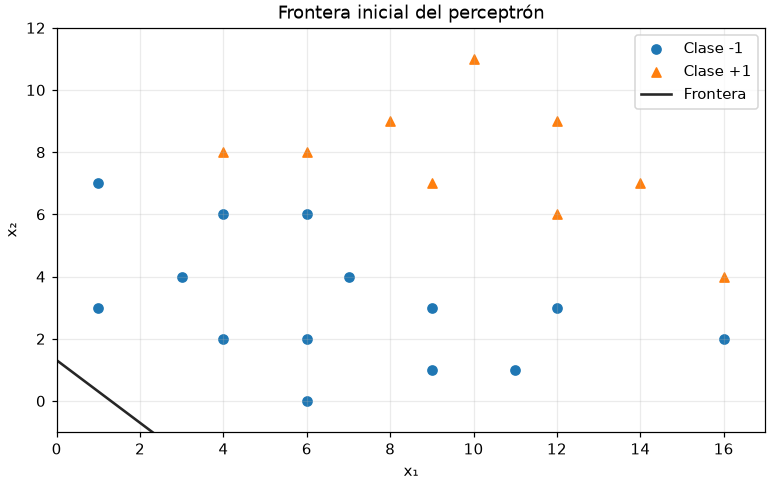

In [ ]:
errores_iniciales = 0
for i in range(len(X)):
    if perceptron_compute(X[i], w_initial) != y[i]:
        errores_iniciales += 1
print(f"Errores con los pesos iniciales = {errores_iniciales}/{len(X)}")
perceptron_plot(X, y, w_initial, "Frontera inicial del perceptrón")

**Respuesta**

En la primera gráfica la recta deja 14 de los 23 puntos mal clasificados. Eso tiene sentido porque todavía no se usaron las clases de los puntos para ajustar los pesos.

## Fase 4 · Entrenamiento del perceptrón

### Pregunta 4.a — Regla de aprendizaje

¿Por qué se fija un máximo de épocas? ¿Qué ocurriría con datos que no se pueden separar con una recta?

Por cada predicción incorrecta se calcula $\Delta=\eta(y-\hat{y})$. Al sesgo se le suma $\Delta$ y a cada peso $w_i$ se le suma $\Delta x_i$.

In [ ]:
def perceptron_learning(X, y, w, lr, max_epochs):
    w = w.copy()
    W_values = []
    E_values = []
    updates = 0

    for _ in range(max_epochs):
        errores = 0
        for punto, etiqueta in zip(X, y):
            prediccion = perceptron_compute(punto, w)
            if prediccion != etiqueta:
                delta = lr * (etiqueta - prediccion)
                w[0] += delta
                w[1] += delta * punto[0]
                w[2] += delta * punto[1]
                errores += 1
                updates += 1

        E_values.append(errores / len(X))
        W_values.append(w.copy())
        if errores == 0:
            break

    return w, len(E_values), updates, W_values, E_values

**Respuesta**

El máximo de épocas evita que el ciclo siga indefinidamente. Si ninguna recta puede separar las clases, siempre quedará algún error y el programa seguirá ajustando pesos hasta llegar al límite.

### Pregunta 4.b — Registro del error

¿Qué significa que la tasa de error llegue a cero?

In [ ]:
_, _, _, pesos_prueba, errores_prueba = perceptron_learning(
    X, y, w_initial, lr=0.5, max_epochs=5
)
for epoca, error in enumerate(errores_prueba, start=1):
    print(f"Época {epoca} → {error:.2%} de error")

Época 1 → 8.70% de error
Época 2 → 13.04% de error
Época 3 → 8.70% de error
Época 4 → 13.04% de error
Época 5 → 8.70% de error


**Respuesta**

Significa que en esa vuelta el perceptrón acertó los 23 puntos. Como los pesos solo se cambian cuando hay un error, quedaron iguales durante toda esa época.

### Pregunta 4.c — Registro de pesos

¿Por qué se guarda una copia de los pesos por época? ¿Qué problema surgiría al graficar si se guardara la misma lista?

In [ ]:
for epoca, pesos in enumerate(pesos_prueba, start=1):
    print(f"Época {epoca} → {[round(peso, 4) for peso in pesos]}")

Época 1 → [-0.241, 3.1853, 1.1841]
Época 2 → [-1.241, 0.1853, 0.1841]
Época 3 → [-1.241, 3.1853, 1.1841]
Época 4 → [-2.241, 0.1853, 2.1841]
Época 5 → [-2.241, 3.1853, 3.1841]


**Respuesta**

Si guardo la misma lista cada vez, al final todas las posiciones del historial muestran los últimos pesos. Con una copia por época sí puedo ver cómo era la recta en cada momento.

## Fase 5 · Entrenamiento con tasa 0.5

### Pregunta 5.a — Convergencia del entrenamiento

¿Convergió el perceptrón? ¿Cómo se comprueba con `E_values` y con la gráfica final?

In [ ]:
w = w_initial.copy()
final_w, epochs, updates, W_values, E_values = perceptron_learning(
    X, y, w, lr=0.5, max_epochs=1000
)

print(f"Pesos iniciales = {[round(peso, 6) for peso in w]}")
print(f"Pesos finales = {[round(peso, 6) for peso in final_w]}")
print(f"Épocas = {epochs}")
print(f"Actualizaciones = {updates}")
print(f"Error final = {E_values[-1]:.2%}")

Pesos iniciales = [-0.240992, 0.185258, 0.184082]
Pesos finales = [-29.240992, 1.185258, 3.184082]
Épocas = 54
Actualizaciones = 143
Error final = 0.00%


**Respuesta**

Sí. Llegó a la época 54 con 143 cambios de pesos. El último número de `E_values` es cero, y en la gráfica final los círculos y los triángulos quedaron en lados opuestos.

### Pregunta 5.b — Comparación de la frontera final con la inicial

¿La frontera final separa correctamente las dos clases? ¿Qué cambió respecto a la inicial?

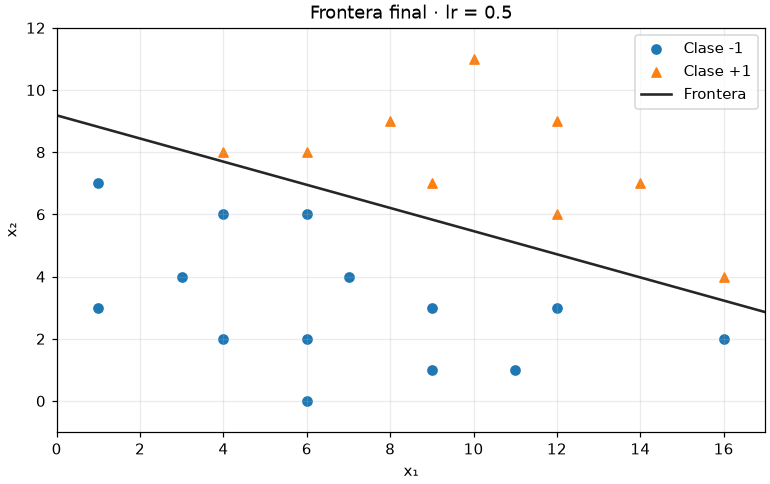

In [ ]:
perceptron_plot(X, y, final_w, "Frontera final · lr = 0.5")

**Respuesta**

La recta final separa los 23 puntos. Comparada con la primera, queda más arriba y menos inclinada. La pendiente cambió de −1.01 a −0.37, aproximadamente.

## Fase 6 · Predicción con nuevas instancias

### Pregunta 6.a — Predicciones

¿Las predicciones son coherentes con la posición de los puntos respecto a la frontera?

In [ ]:
from IPython.display import Markdown, display

X_test = [[5, 5], [10, 6], [6, 10]]
y_test = []
for punto in X_test:
    y_test.append(perceptron_compute(punto, final_w))

filas = ["| Instancia | Salida predicha |", "|---|---:|"]
for punto, etiqueta in zip(X_test, y_test):
    filas.append(f"| `{punto}` | {etiqueta:+d} |")
display(Markdown("\n".join(filas)))

| Instancia | Salida predicha |
|---|---:|
| `[5, 5]` | -1 |
| `[10, 6]` | +1 |
| `[6, 10]` | +1 |

**Respuesta**

Sí. El punto $[5,5]$ quedó debajo de la recta y salió −1. Los puntos $[10,6]$ y $[6,10]$ quedaron arriba y salieron +1.

### Pregunta 6.b — Conjunto extendido

¿Los puntos nuevos están en las regiones esperadas? ¿Qué predicción merece más atención?

Total del conjunto extendido = 26


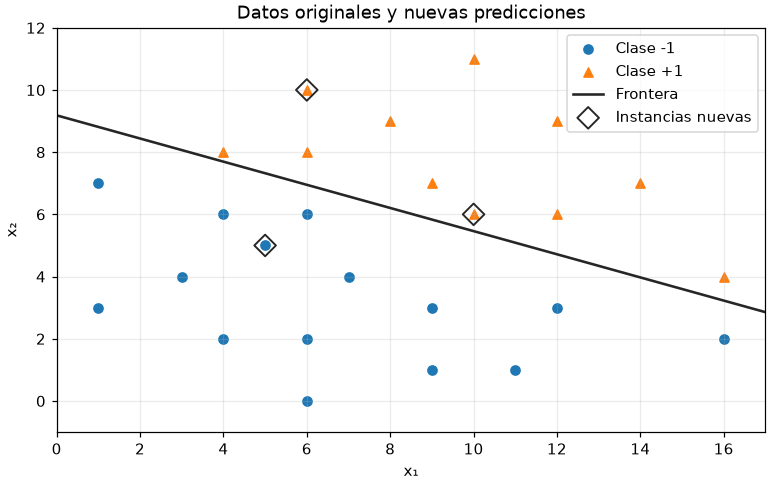

In [ ]:
X_extendido = X + X_test
y_extendido = y + y_test
print(f"Total del conjunto extendido = {len(X_extendido)}")

fig, ax = plt.subplots(figsize=(7, 4.4), layout="constrained")
dibujar_frontera(ax, X_extendido, y_extendido, final_w, "Datos originales y nuevas predicciones")
ax.scatter(
    [punto[0] for punto in X_test], [punto[1] for punto in X_test],
    marker="D", s=100, facecolors="none", edgecolors="#262626",
    linewidths=1.25, label="Instancias nuevas", zorder=4,
)
ax.legend()
plt.show()

**Respuesta**

El punto que más llama la atención es $[10,6]$. Salió +1, pero está apenas 0.54 unidades por encima de la recta en vertical. Si la recta subiera un poco ahí, podría cambiar de clase. La gráfica muestra las predicciones porque no tenemos las etiquetas reales de los tres puntos.

## Fase 7 · Evolución de la frontera de decisión

### Pregunta 7.a — Seis estados del entrenamiento

¿Cómo cambia la frontera durante las actualizaciones? ¿El cambio parece estable o brusco?

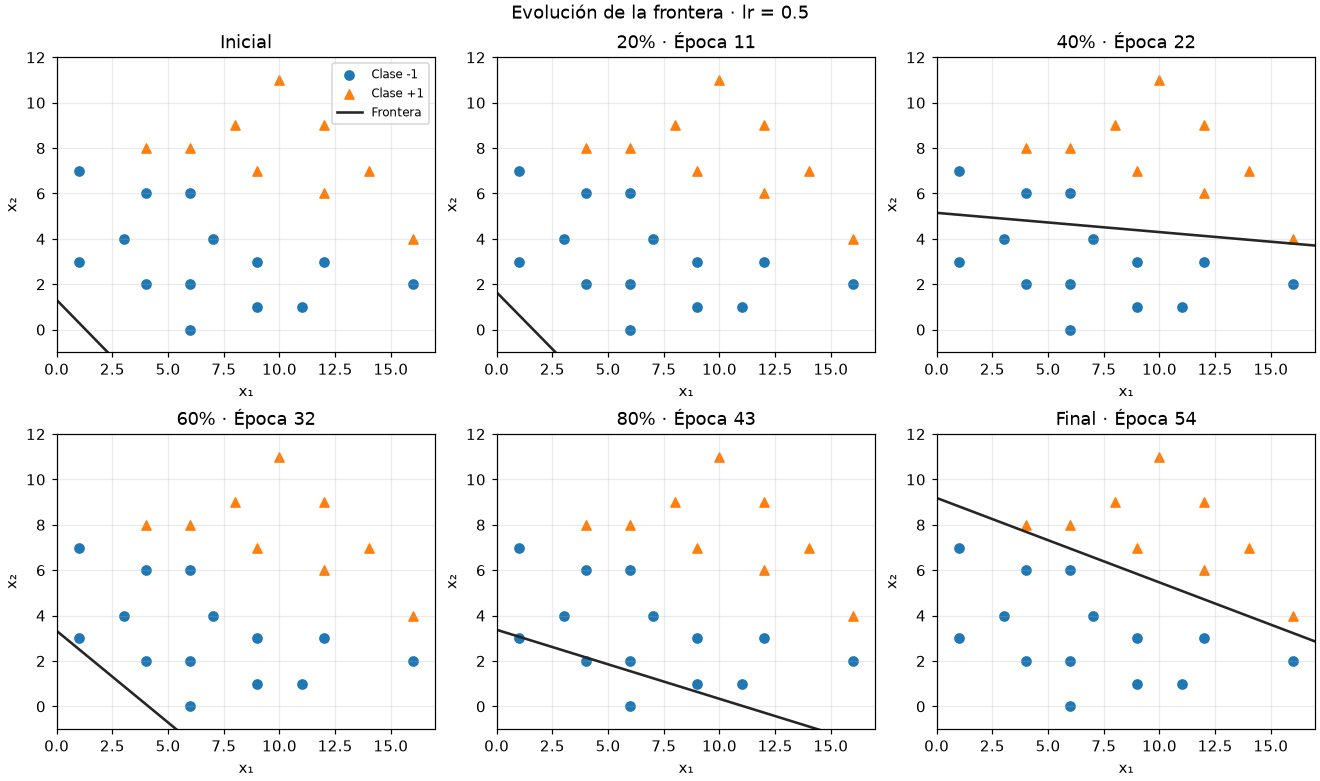

In [ ]:
def estados_entrenamiento(w_inicial, historial):
    total = len(historial)
    pesos = [w_inicial] + historial
    estados = [("Inicial", w_inicial)]
    if total < 6:
        for epoca in range(1, total + 1):
            estados.append((f"Época {epoca}", pesos[epoca]))
        return estados

    for porcentaje in [20, 40, 60, 80]:
        epoca = round(total * porcentaje / 100)
        estados.append((f"{porcentaje}% · Época {epoca}", pesos[epoca]))
    estados.append((f"Final · Época {total}", pesos[-1]))
    return estados

def graficar_evolucion(X, y, w_inicial, historial, titulo):
    estados = estados_entrenamiento(w_inicial, historial)
    filas = (len(estados) + 2) // 3
    fig, ejes = plt.subplots(filas, 3, figsize=(12, 3.15 * filas + 0.8),
                             squeeze=False, layout="constrained")
    ejes = ejes.flatten()
    for i in range(len(estados)):
        subtitulo, pesos = estados[i]
        dibujar_frontera(ejes[i], X, y, pesos, subtitulo)
    for i in range(len(estados), len(ejes)):
        ejes[i].set_visible(False)

    fig.suptitle(titulo)
    ejes[0].legend(loc="upper right", fontsize=8)
    plt.show()

graficar_evolucion(X, y, w, W_values, "Evolución de la frontera · lr = 0.5")

**Respuesta**

La recta cambia a saltos. Al 40 % se ve casi horizontal y al 60 % vuelve a inclinarse. Al final queda más arriba y pasa entre los dos grupos.

### Pregunta 7.b — Inclinación y desplazamiento

¿Qué pesos determinan la inclinación? ¿Cómo interviene el sesgo en el desplazamiento?

In [ ]:
filas = ["| Estado | Pendiente | Intercepto en x₂ |", "|---|---:|---:|"]
for estado, (w0, w1, w2) in estados_entrenamiento(w, W_values):
    if w2 != 0:
        filas.append(f"| {estado} | {-w1 / w2:.3f} | {-w0 / w2:.3f} |")
    else:
        filas.append(f"| {estado} | Sin pendiente finita | — |")
display(Markdown("\n".join(filas)))

| Estado | Pendiente | Intercepto en x₂ |
|---|---:|---:|
| Inicial | -1.006 | 1.309 |
| 20% · Época 11 | -1.000 | 1.646 |
| 40% · Época 22 | -0.085 | 5.147 |
| 60% · Época 32 | -0.807 | 3.326 |
| 80% · Época 43 | -0.304 | 3.374 |
| Final · Época 54 | -0.372 | 9.183 |

**Respuesta**

Para ver la inclinación hay que mirar los dos pesos, porque la pendiente es $-w_1/w_2$. Si dejo fijo $w_2$, al cambiar el sesgo cambia el punto donde la recta corta el eje $x_2$. Si mantengo también fijo $w_1$, la recta se mueve sin girar.

## Fase 8 · Evolución del error

### Pregunta 8.a — Curva de error

¿El error disminuye en cada época? ¿Por qué puede aumentar o mantenerse igual?

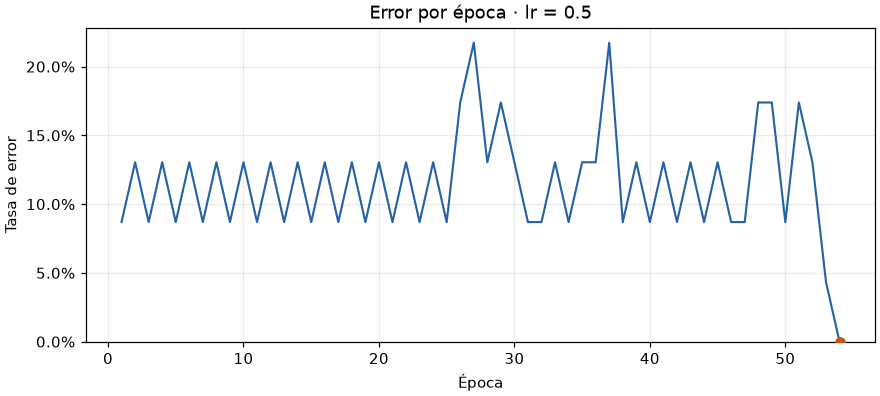

In [ ]:
from matplotlib.ticker import PercentFormatter

def plot_error(E_values, title):
    epocas = range(1, len(E_values) + 1)
    fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
    ax.plot(epocas, E_values, color="#2563a6", lw=1.4)
    ax.scatter(len(E_values), E_values[-1], color="#c4551a", zorder=3)
    ax.set(xlabel="Época", ylabel="Tasa de error", title=title, ylim=(0, None))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.grid(alpha=0.25)
    plt.show()

plot_error(E_values, "Error por época · lr = 0.5")

**Respuesta**

El error sube y baja. En la primera época hubo 2 errores y en la segunda hubo 3. Una corrección puede ayudar al punto que causó el cambio y al mismo tiempo dejar otro punto del lado equivocado.

### Pregunta 8.b — Alcance de la convergencia

¿Qué significa un error final de cero? ¿Garantiza que el modelo acierte en datos futuros?

**Respuesta**

Cero significa que acertó todos los puntos que usó para entrenar. Para saber cómo le iría con puntos nuevos, tendría que probarlo con datos que tengan su clase real.

## Fase 9 · Comparación de tasas de aprendizaje

### Pregunta 9.a — Condiciones del experimento

¿Por qué se usan los mismos pesos iniciales al comparar las tasas de aprendizaje?

In [ ]:
tasas = [0.3, 0.5, 0.8]
w_comun = w_initial.copy()
resultados = {}

for tasa in tasas:
    resultados[tasa] = perceptron_learning(
        X, y, w_comun.copy(), lr=tasa, max_epochs=1000
    )

print(f"Pesos iniciales comunes = {[round(peso, 6) for peso in w_comun]}")

Pesos iniciales comunes = [-0.240992, 0.185258, 0.184082]


**Respuesta**

Si cada prueba empieza con pesos distintos, también empieza con una recta distinta. Al usar los mismos pesos y el mismo orden de los puntos, puedo comparar qué cambia al variar la tasa.

### Pregunta 9.b — Comparación gráfica

¿Qué tasa convergió en menos épocas? ¿Podemos concluir que siempre es la mejor?

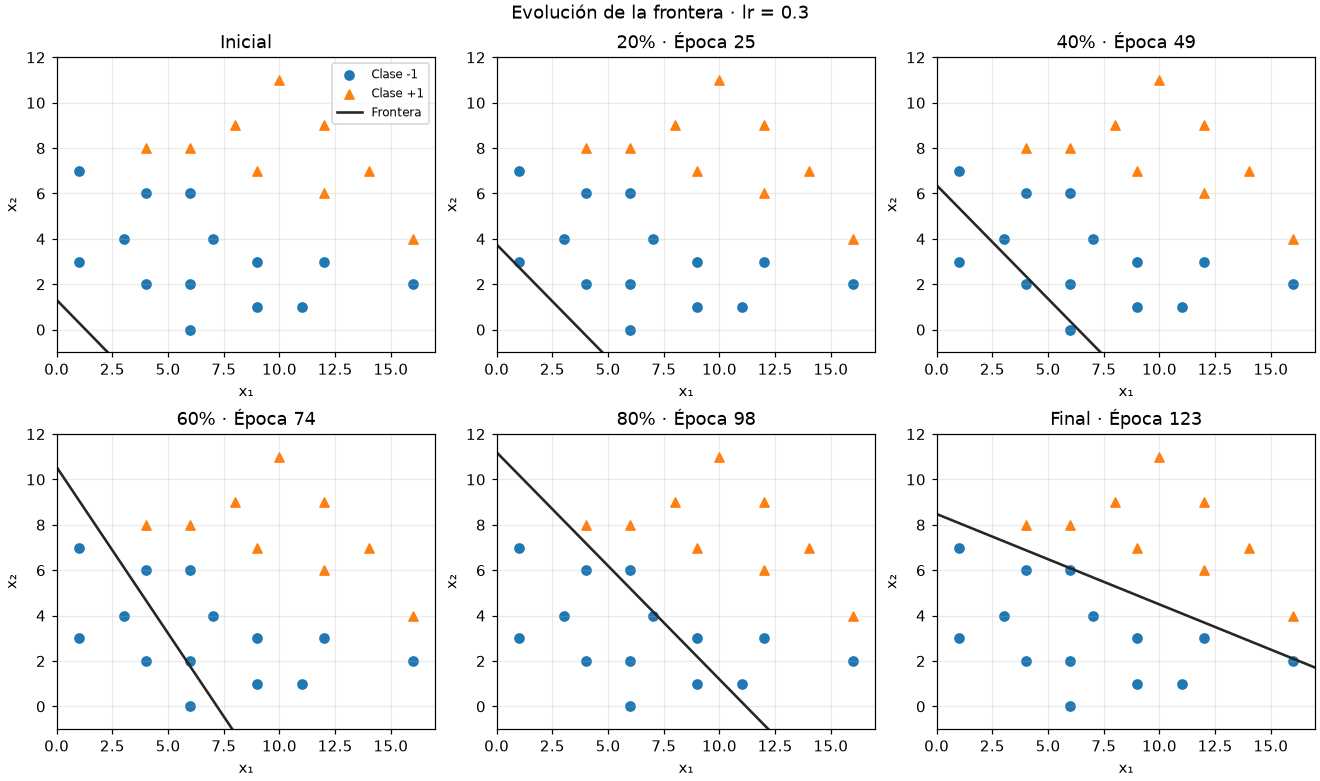

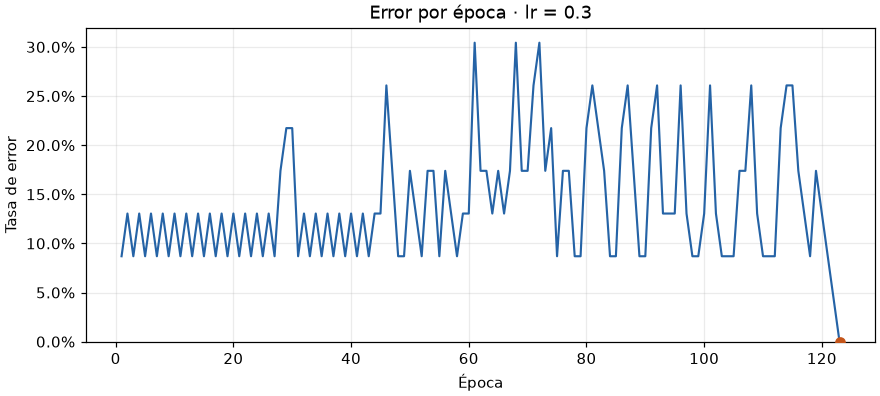

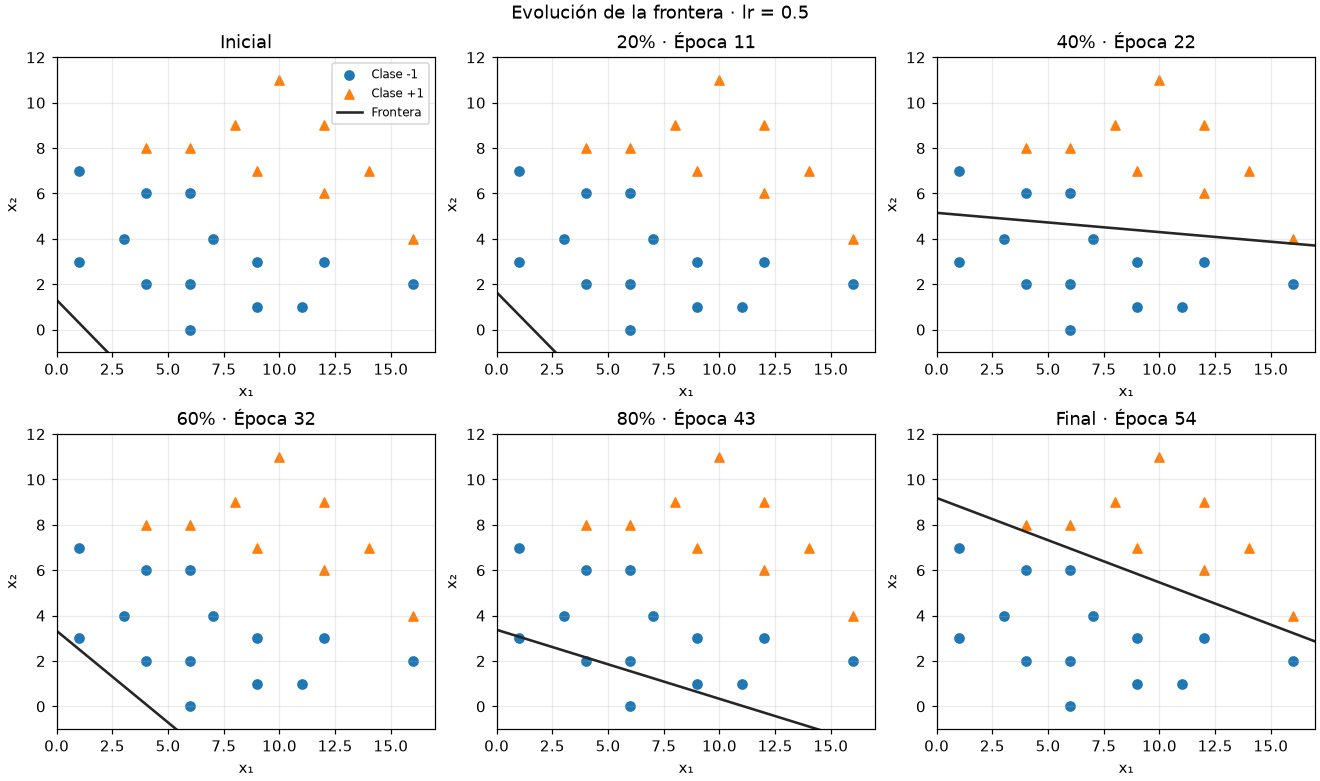

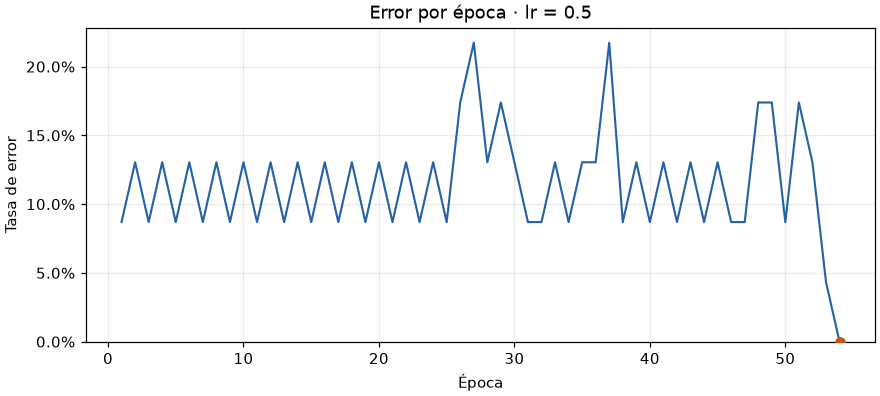

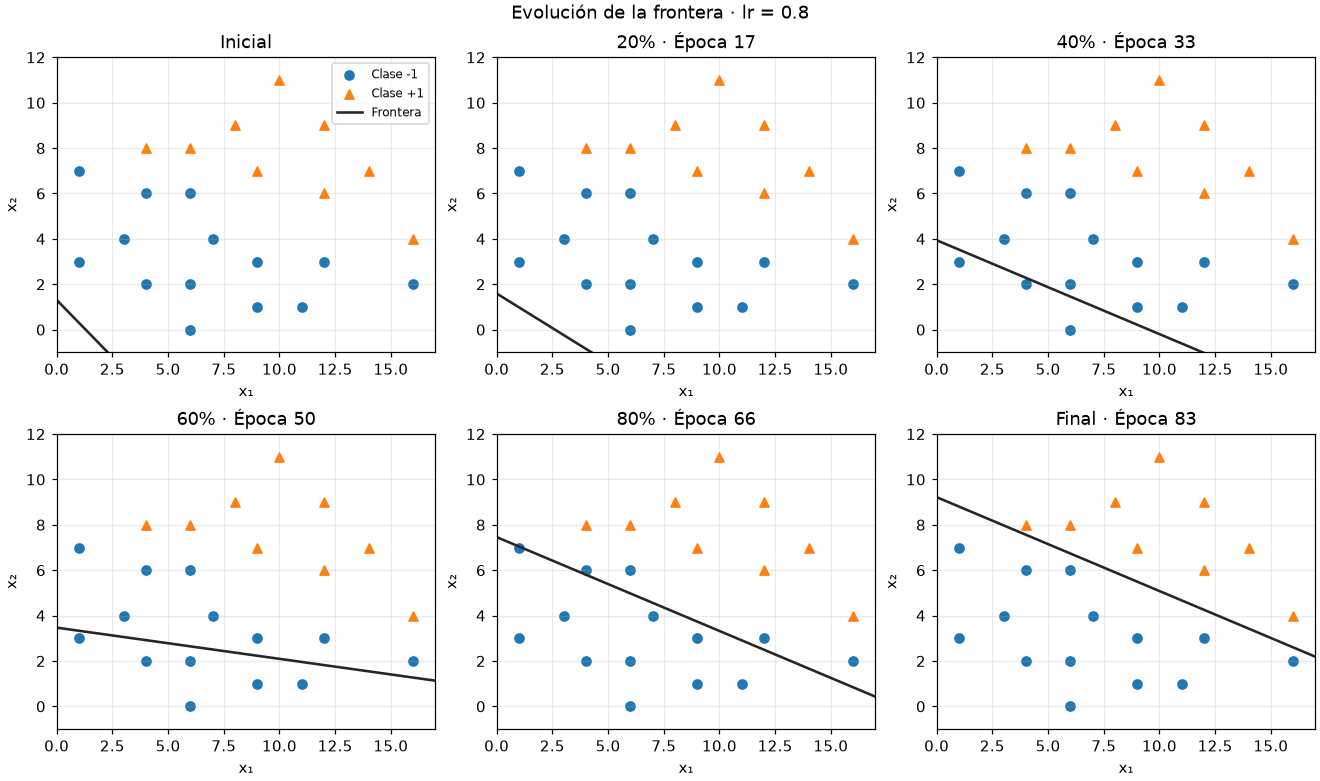

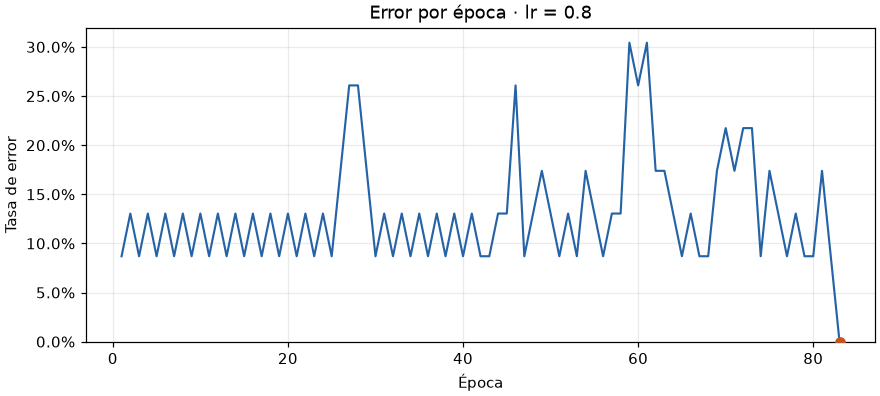

In [ ]:
for tasa in tasas:
    _, _, _, historial, errores = resultados[tasa]
    graficar_evolucion(X, y, w_comun, historial, f"Evolución de la frontera · lr = {tasa}")
    plot_error(errores, f"Error por época · lr = {tasa}")

**Respuesta**

La tasa 0.5 fue la más rápida en esta prueba: tardó 54 épocas. Con 0.8 fueron 83 y con 0.3 fueron 123. Con otros pesos iniciales o con otros datos, el orden podría cambiar.

### Pregunta 9.c — Tabla comparativa

¿Los pesos finales son iguales? ¿Cómo pueden clasificar bien los datos varios vectores de pesos?

In [ ]:
filas = [
    "| lr | Épocas | Actualizaciones | Error final | Pesos finales [w₀, w₁, w₂] |",
    "|---:|---:|---:|---:|---|",
]
for tasa, (pesos, epocas, cambios, _, errores) in resultados.items():
    pesos_texto = ", ".join(f"{peso:.4f}" for peso in pesos)
    filas.append(f"| {tasa} | {epocas} | {cambios} | {errores[-1]:.2%} | [{pesos_texto}] |")
display(Markdown("\n".join(filas)))

| lr | Épocas | Actualizaciones | Error final | Pesos finales [w₀, w₁, w₂] |
|---:|---:|---:|---:|---|
| 0.3 | 123 | 400 | 0.00% | [-42.2410, 1.9853, 4.9841] |
| 0.5 | 54 | 143 | 0.00% | [-29.2410, 1.1853, 3.1841] |
| 0.8 | 83 | 249 | 0.00% | [-75.4410, 3.3853, 8.1841] |

**Respuesta**

Los pesos finales son distintos, aunque las tres pruebas llegaron a cero errores. Hay espacio entre los dos grupos para dibujar varias rectas que dejan cada punto del lado correcto.

## Conclusiones

- Al inicio la recta dejaba 14 puntos mal clasificados. Con la tasa 0.5, después de 54 épocas, logró separar los 23 puntos.
- Me llamó la atención que con 0.8 tardó más que con 0.5. Las tres tasas llegaron a cero errores, pero cada una terminó con una recta diferente.